# Notebook 03 — Commodity Forecasting & Cross-Domain Ablation

**Purpose:** Evaluate whether DS-4 material-financial signals add predictive value for next-session commodity returns beyond price-derived features.

## Methodology and guardrails
- Target: next available row's `daily_return` within each commodity (`shift(-1)` after sorting by date).
- Time-based split within each commodity: earliest 70% train, next 15% validation, latest 15% test.
- Compare a zero-return baseline and Ridge regression; optionally HistGradientBoosting if available.
- Ablation: price/technical features only vs. price/technical + DS-4 cross-domain features.
- Model choice is made on validation MAE; final test is reported once.
- This is a sample-data experiment, not investment advice. Historical association does not establish tradable alpha.
- Confirm upstream feature calculations are point-in-time safe before making claims about real-world forecasting.


In [1]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

# Search paths support running from ML/notebooks, ML/, or project root.
DATA_ROOT_CANDIDATES = [
    Path(os.environ["MATRISK_DATA_ROOT"]) if os.environ.get("MATRISK_DATA_ROOT") else None,
    Path("../../Data/raw"), Path("../../Data"), Path("../Data/raw"), Path("../Data"),
    Path("Data/raw"), Path("Data"), Path("data/raw"), Path("data/external"),
    Path("/mnt/data")
]
DATA_ROOT_CANDIDATES = [p for p in DATA_ROOT_CANDIDATES if p is not None]
OUTPUT_DIR = Path("../outputs/notebook_03")
try:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
except OSError:
    OUTPUT_DIR = Path.cwd() / "outputs" / "notebook_03"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def locate_file(filename):
    for root in DATA_ROOT_CANDIDATES:
        candidate = root / filename
        if candidate.is_file():
            print(f"Found {filename}: {candidate.resolve()}")
            return candidate
    raise FileNotFoundError(
        f"Could not find {filename}. Set MATRISK_DATA_ROOT to the folder containing the CSVs. "
        f"Searched: {[str(p.resolve()) for p in DATA_ROOT_CANDIDATES]}"
    )

DS2_PATH = locate_file("DS2_commodity_prices_10yr.csv")
DS4_PATH = locate_file("DS4_crossdomain_features_daily.csv")

ds2 = pd.read_csv(DS2_PATH, parse_dates=["date"])
ds4 = pd.read_csv(DS4_PATH, parse_dates=["date"])
print("DS2:", ds2.shape, "| DS4:", ds4.shape)
display(ds2.head(3))
display(ds4.head(3))

Found DS2_commodity_prices_10yr.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS2_commodity_prices_10yr.csv
Found DS4_crossdomain_features_daily.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS4_crossdomain_features_daily.csv
DS2: (22952, 24) | DS4: (22952, 12)


,date,commodity,open,high,low,close,volume,daily_return,return_5d,return_21d,...,sma_63,bollinger_upper,bollinger_lower,bollinger_z,rsi_14,macd,macd_signal,momentum_10d,momentum_21d,term_spread
0,2014-01-02,Steel_HRC,598.5489,602.7788,595.2943,598.4254,1109,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,1.670683
1,2014-01-03,Steel_HRC,573.8080,578.2438,572.2654,574.4014,796,-0.040973,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.539000,-0.299444,NaN,NaN,-6.634311
2,2014-01-06,Steel_HRC,575.2184,579.4599,573.8479,576.0968,2226,0.002947,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.634219,-0.436647,NaN,NaN,-2.787013


,date,commodity,mqi,supply_disruption_prob,substitution_elasticity,green_premium_per_kg,carbon_intensity_virgin,carbon_intensity_recycled,herfindahl_index,mqi_5d_trend,mqi_21d_trend,mqi_63d_trend
0,2014-01-02,Steel_HRC,78.30,0.1809,0.4194,0.149,2.08,0.42,0.0729,NaN,NaN,NaN
1,2014-01-03,Steel_HRC,77.77,0.1727,0.3940,0.147,2.11,0.40,0.0767,NaN,NaN,NaN
2,2014-01-06,Steel_HRC,77.41,0.1729,0.3967,0.152,2.08,0.39,0.0881,NaN,NaN,NaN


In [2]:
# Audit keys and merge DS-2 with DS-4.
KEYS = ["date", "commodity"]
for name, frame in [("DS2", ds2), ("DS4", ds4)]:
    missing_keys = frame[KEYS].isna().any(axis=1).sum()
    duplicate_keys = frame.duplicated(KEYS).sum()
    print(f"{name}: missing keys={missing_keys}, duplicate (date, commodity) keys={duplicate_keys}")
    if missing_keys or duplicate_keys:
        raise ValueError(f"{name} has missing or duplicate merge keys; investigate before modelling.")

merged = ds2.merge(ds4, on=KEYS, how="left", validate="one_to_one", indicator=True)
print("Merge status:", merged["_merge"].value_counts(dropna=False).to_dict())
if (merged["_merge"] != "both").any():
    raise ValueError("DS-2 and DS-4 do not have a complete one-to-one key match.")
merged = merged.drop(columns="_merge").sort_values(["commodity", "date"]).reset_index(drop=True)

# Build forward target within commodity; current-row features predict next row's return.
merged["target_next_return"] = merged.groupby("commodity", sort=False)["daily_return"].shift(-1)
print("Rows:", len(merged), "| commodities:", merged["commodity"].nunique())
print("Target missing (expected last row per commodity plus initial return warm-up):",
      int(merged["target_next_return"].isna().sum()))
display(merged.groupby("commodity")["date"].agg(["min", "max", "count"]))

DS2: missing keys=0, duplicate (date, commodity) keys=0
DS4: missing keys=0, duplicate (date, commodity) keys=0
Merge status: {'both': 22952, 'left_only': 0, 'right_only': 0}
Rows: 22952 | commodities: 8
Target missing (expected last row per commodity plus initial return warm-up): 8


,min,max,count
commodity,,,
Aluminium,2014-01-02,2024-12-31,2869
Cobalt_Index,2014-01-02,2024-12-31,2869
Copper,2014-01-02,2024-12-31,2869
Iron_Ore,2014-01-02,2024-12-31,2869
Lithium_ETF,2014-01-02,2024-12-31,2869
Nickel,2014-01-02,2024-12-31,2869
RareEarth_ETF,2014-01-02,2024-12-31,2869
Steel_HRC,2014-01-02,2024-12-31,2869


In [3]:
# Define feature sets. Do not use target, date, commodity, or future-derived fields.
# Price/technical fields are known at the current row only if upstream calculations are point-in-time safe.
price_features = [
    "open", "high", "low", "close", "volume", "daily_return", "return_5d",
    "return_21d", "volatility_5d_ann", "volatility_21d_ann", "volatility_63d_ann",
    "sma_21", "sma_63", "bollinger_upper", "bollinger_lower", "bollinger_z",
    "rsi_14", "macd", "macd_signal", "momentum_10d", "momentum_21d", "term_spread"
]
cross_features = [
    "mqi", "supply_disruption_prob", "substitution_elasticity", "green_premium_per_kg",
    "carbon_intensity_virgin", "carbon_intensity_recycled", "herfindahl_index",
    "mqi_5d_trend", "mqi_21d_trend", "mqi_63d_trend"
]
price_features = [c for c in price_features if c in merged.columns]
cross_features = [c for c in cross_features if c in merged.columns]
feature_sets = {
    "price_only": price_features,
    "price_plus_cross_domain": price_features + cross_features
}
if not price_features:
    raise ValueError("No price feature columns were found.")
print("Price-only features:", len(price_features))
print("Cross-domain features:", len(cross_features))
display(pd.DataFrame({
    "feature_set": list(feature_sets.keys()),
    "n_features": [len(v) for v in feature_sets.values()]
}))

Price-only features: 22
Cross-domain features: 10


,feature_set,n_features
0,price_only,22
1,price_plus_cross_domain,32


In [4]:
# Chronological per-commodity split. Never shuffle time-series rows.
model_data = merged.dropna(subset=["target_next_return"]).copy()
model_data = model_data.sort_values(["commodity", "date"]).reset_index(drop=True)
model_data["_split"] = ""

split_rows = []
for commodity, group in model_data.groupby("commodity", sort=False):
    idx = group.index.to_numpy()
    n = len(idx)
    n_train = int(np.floor(n * 0.70))
    n_val = int(np.floor(n * 0.15))
    if n_train < 50 or n_val < 10 or n - n_train - n_val < 10:
        raise ValueError(f"Insufficient rows for chronological split: {commodity}, n={n}")
    model_data.loc[idx[:n_train], "_split"] = "train"
    model_data.loc[idx[n_train:n_train+n_val], "_split"] = "validation"
    model_data.loc[idx[n_train+n_val:], "_split"] = "test"
    split_rows.append({
        "commodity": commodity, "n": n,
        "train_n": n_train, "validation_n": n_val, "test_n": n-n_train-n_val,
        "train_end": group.iloc[n_train-1]["date"],
        "validation_end": group.iloc[n_train+n_val-1]["date"],
        "test_start": group.iloc[n_train+n_val]["date"],
    })

split_report = pd.DataFrame(split_rows)
display(split_report)
assert (model_data.groupby(["commodity", "_split"])["date"].min().unstack()["train"] <
        model_data.groupby(["commodity", "_split"])["date"].min().unstack()["validation"]).all()
assert (model_data.groupby(["commodity", "_split"])["date"].min().unstack()["validation"] <
        model_data.groupby(["commodity", "_split"])["date"].min().unstack()["test"]).all()
split_report.to_csv(OUTPUT_DIR / "chronological_split_report.csv", index=False)

,commodity,n,train_n,validation_n,test_n,train_end,validation_end,test_start
0,Aluminium,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
1,Cobalt_Index,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
2,Copper,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
3,Iron_Ore,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
4,Lithium_ETF,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
5,Nickel,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
6,RareEarth_ETF,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08
7,Steel_HRC,2868,2007,430,431,2021-09-10,2023-05-05,2023-05-08


In [5]:
# Fit baselines and candidate models. Model selection uses validation MAE only.
# HistGradientBoosting is included as a nonlinear candidate but can be removed if too slow.
models = {
    "ZeroReturn": DummyRegressor(strategy="constant", constant=0.0),
    "Ridge": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        Ridge(alpha=10.0)
    ),
    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        HistGradientBoostingRegressor(
            max_iter=100, learning_rate=0.06, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=42
        )
    )
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "R2": float(r2_score(y_true, y_pred)) if len(np.unique(y_true)) > 1 else float("nan"),
        "directional_accuracy": (
            float(np.mean(np.sign(y_true[np.asarray(y_pred) != 0]) ==
                           np.sign(np.asarray(y_pred)[np.asarray(y_pred) != 0])))
            if np.any(np.asarray(y_pred) != 0) else float("nan")
        )
    }

result_rows = []
fitted_validation = {}
for feature_set_name, features in feature_sets.items():
    for model_name, estimator in models.items():
        train_df = model_data[model_data["_split"] == "train"]
        val_df = model_data[model_data["_split"] == "validation"]
        X_train = train_df[features]
        y_train = train_df["target_next_return"].astype(float)
        X_val = val_df[features]
        y_val = val_df["target_next_return"].astype(float)

        estimator.fit(X_train, y_train)
        pred_val = estimator.predict(X_val)
        metrics_row = {
            "feature_set": feature_set_name,
            "model": model_name,
            "n_features": len(features),
            "validation_n": len(val_df),
            **regression_metrics(y_val, pred_val)
        }
        result_rows.append(metrics_row)
        fitted_validation[(feature_set_name, model_name)] = estimator
        print(f"Completed validation: {feature_set_name} / {model_name}")

validation_results = pd.DataFrame(result_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

best_config = (
    validation_results.sort_values("MAE")
    .iloc[0][["feature_set", "model"]].to_dict()
)
print("Validation-selected configuration:", best_config)

Completed validation: price_only / ZeroReturn
Completed validation: price_only / Ridge
Completed validation: price_only / HistGradientBoosting
Completed validation: price_plus_cross_domain / ZeroReturn
Completed validation: price_plus_cross_domain / Ridge
Completed validation: price_plus_cross_domain / HistGradientBoosting


,feature_set,model,n_features,validation_n,MAE,RMSE,R2,directional_accuracy
0,price_only,ZeroReturn,22,3440,0.016630,0.021194,-0.000050,NaN
1,price_plus_cross_domain,ZeroReturn,32,3440,0.016630,0.021194,-0.000050,NaN
2,price_plus_cross_domain,HistGradientBoosting,32,3440,0.016631,0.021182,0.001056,0.496802
3,price_plus_cross_domain,Ridge,32,3440,0.016638,0.021199,-0.000547,0.511628
4,price_only,Ridge,22,3440,0.016639,0.021199,-0.000518,0.505523
5,price_only,HistGradientBoosting,22,3440,0.016670,0.021216,-0.002142,0.494186


Validation-selected configuration: {'feature_set': 'price_only', 'model': 'ZeroReturn'}


In [6]:
# Refit selected configuration on train + validation, then evaluate the untouched test period once.
best_feature_set = best_config["feature_set"]
best_model_name = best_config["model"]
best_features = feature_sets[best_feature_set]

trainval_df = model_data[model_data["_split"].isin(["train", "validation"])]
test_df = model_data[model_data["_split"] == "test"]
final_model = models[best_model_name]
final_model.fit(trainval_df[best_features], trainval_df["target_next_return"].astype(float))

test_pred = final_model.predict(test_df[best_features])
test_metrics = regression_metrics(test_df["target_next_return"].astype(float), test_pred)
test_result = {
    "selected_feature_set": best_feature_set,
    "selected_model": best_model_name,
    "n_test": len(test_df),
    **test_metrics
}
print("Held-out test result (one final evaluation):")
display(pd.DataFrame([test_result]))

# Also report the zero-return baseline on exactly the same test rows.
zero_pred = np.zeros(len(test_df), dtype=float)
baseline_test = regression_metrics(test_df["target_next_return"].astype(float), zero_pred)
test_comparison = pd.DataFrame([
    {"model": "ZeroReturn baseline", **baseline_test},
    {"model": f"{best_model_name} / {best_feature_set}", **test_metrics},
])
display(test_comparison)
test_comparison.to_csv(OUTPUT_DIR / "heldout_test_comparison.csv", index=False)

predictions = test_df[["date", "commodity", "target_next_return"]].copy()
predictions["prediction"] = test_pred
predictions["absolute_error"] = np.abs(predictions["target_next_return"] - predictions["prediction"])
predictions.to_csv(OUTPUT_DIR / "heldout_test_predictions.csv", index=False)

# Per-commodity test results help reveal whether aggregate performance hides failures.
per_commodity = []
for commodity, part in predictions.groupby("commodity"):
    per_commodity.append({
        "commodity": commodity,
        "n_test": len(part),
        **regression_metrics(part["target_next_return"].to_numpy(), part["prediction"].to_numpy())
    })
per_commodity = pd.DataFrame(per_commodity)
display(per_commodity)
per_commodity.to_csv(OUTPUT_DIR / "heldout_test_by_commodity.csv", index=False)

Held-out test result (one final evaluation):


,selected_feature_set,selected_model,n_test,MAE,RMSE,R2,directional_accuracy
0,price_only,ZeroReturn,3448,0.016272,0.020794,-0.000216,NaN


,model,MAE,RMSE,R2,directional_accuracy
0,ZeroReturn baseline,0.016272,0.020794,-0.000216,NaN
1,ZeroReturn / price_only,0.016272,0.020794,-0.000216,NaN


,commodity,n_test,MAE,RMSE,R2,directional_accuracy
0,Aluminium,431,0.012182,0.015382,-0.000645,NaN
1,Cobalt_Index,431,0.015243,0.019166,-0.006967,NaN
2,Copper,431,0.013405,0.016718,-0.002098,NaN
3,Iron_Ore,431,0.015701,0.019878,-0.000001,NaN
4,Lithium_ETF,431,0.019736,0.024774,-0.001941,NaN
5,Nickel,431,0.018371,0.023304,-0.000013,NaN
6,RareEarth_ETF,431,0.021355,0.026508,-0.010924,NaN
7,Steel_HRC,431,0.014183,0.017915,-0.005226,NaN


,feature_set,model,validation_MAE,validation_RMSE,validation_R2,validation_directional_accuracy
0,price_only,ZeroReturn,0.01663,0.021194,-0.00005,0.505523
1,price_plus_cross_domain,ZeroReturn,0.01663,0.021194,-0.00005,0.496802


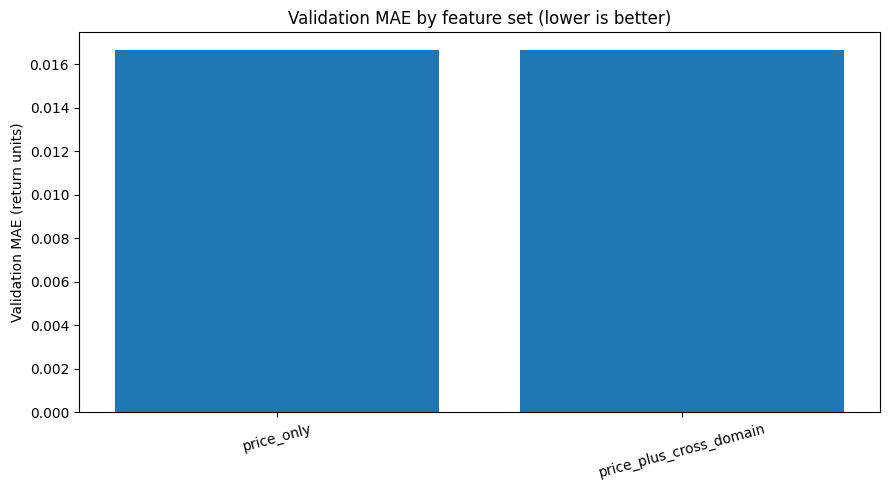

{
  "ds2_path": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS2_commodity_prices_10yr.csv",
  "ds4_path": "C:\\Users\\Amey Ravindra Pandit\\Downloads\\MAT Risk\\Data\\raw\\DS4_crossdomain_features_daily.csv",
  "ds2_rows": 22952,
  "ds4_rows": 22952,
  "merged_rows": 22952,
  "model_rows": 22944,
  "commodities": [
    "Aluminium",
    "Cobalt_Index",
    "Copper",
    "Iron_Ore",
    "Lithium_ETF",
    "Nickel",
    "RareEarth_ETF",
    "Steel_HRC"
  ],
  "target": "next available row's daily_return within each commodity",
  "split": "chronological per commodity: 70% train / 15% validation / 15% test",
  "selection_metric": "validation MAE",
  "selected_configuration": {
    "feature_set": "price_only",
    "model": "ZeroReturn"
  },
  "heldout_test_metrics": {
    "selected_feature_set": "price_only",
    "selected_model": "ZeroReturn",
    "n_test": 3448,
    "MAE": 0.016272171113689095,
    "RMSE": 0.02079356082193361,
    "R2": -0.00021638123405698373,
    "d

In [7]:
# Ablation: compare the best validation-selected model for each feature set on validation.
# This is not a substitute for the final test comparison above.
ablation = (
    validation_results.sort_values("MAE")
    .groupby("feature_set", as_index=False)
    .first()[["feature_set", "model", "MAE", "RMSE", "R2", "directional_accuracy"]]
    .rename(columns={"MAE": "validation_MAE", "RMSE": "validation_RMSE",
                     "R2": "validation_R2", "directional_accuracy": "validation_directional_accuracy"})
)
display(ablation)
ablation.to_csv(OUTPUT_DIR / "cross_domain_ablation_validation.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(ablation["feature_set"], ablation["validation_MAE"])
ax.set_title("Validation MAE by feature set (lower is better)")
ax.set_ylabel("Validation MAE (return units)")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "cross_domain_ablation_validation.png", dpi=140)
plt.show()

# Basic checks and reproducibility metadata.
assert not model_data[["date", "commodity"]].isna().any().any()
assert model_data.duplicated(["date", "commodity"]).sum() == 0
for commodity, part in model_data.groupby("commodity"):
    dates = {s: part.loc[part["_split"] == s, "date"] for s in ["train", "validation", "test"]}
    assert dates["train"].max() < dates["validation"].min() < dates["test"].min()

summary = {
    "ds2_path": str(DS2_PATH.resolve()),
    "ds4_path": str(DS4_PATH.resolve()),
    "ds2_rows": int(len(ds2)),
    "ds4_rows": int(len(ds4)),
    "merged_rows": int(len(merged)),
    "model_rows": int(len(model_data)),
    "commodities": sorted(model_data["commodity"].unique().tolist()),
    "target": "next available row's daily_return within each commodity",
    "split": "chronological per commodity: 70% train / 15% validation / 15% test",
    "selection_metric": "validation MAE",
    "selected_configuration": {"feature_set": best_feature_set, "model": best_model_name},
    "heldout_test_metrics": test_result,
    "warning": "Synthetic/sample data and upstream feature timing not independently verified; do not claim tradable alpha.",
    "outputs": sorted(p.name for p in OUTPUT_DIR.iterdir())
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("All outputs saved to:", OUTPUT_DIR.resolve())